# Laboratorul 4 — DDPM de la zero

**Student:** Iatco Marcel

## Scopul lucrării

În această lucrare construiesc pas cu pas un model de difuzie DDPM (*Denoising Diffusion Probabilistic Model*) care generează imagini Fashion-MNIST. Concret:

* definesc două programe de zgomot (liniar și cosinus) și procesul direct de difuzie;
* antrenez o rețea U-Net mică să recunoască zgomotul dintr-o imagine;
* generez imagini noi pornind de la zgomot pur, cu DDPM (1000 de pași) și cu DDIM (mai puțini pași);
* compar timpul de generare cu calitatea și compar cele două programe de zgomot.

**Unde rulează:** Jupyter Notebook (`jupyter notebook`, din mediul conda `difuzie`) sau Google Colab. Codul detectează singur dacă există GPU; pe CPU antrenarea durează mai mult, dar parametrii rămân cei din PDF.

## 0. Pregătirea mediului

Import bibliotecile, aleg dispozitivul de calcul și fixez seed-ul 42, ca rezultatele să fie reproductibile.

Bibliotecile necesare (instalare o singură dată, în terminal, în mediul de lucru):

```bash
pip install torch torchvision matplotlib numpy pandas jupyter
```

In [1]:
%matplotlib inline
import math, time, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from torch.utils.data import DataLoader, TensorDataset

# Dispozitivul: GPU (CUDA) dacă există, altfel CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def fixeaza_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

fixeaza_seed(42)

def sync():
    # pe GPU, operațiile sunt asincrone: așteptăm terminarea lor înainte de a citi timpul
    if device.type == "cuda":
        torch.cuda.synchronize()

FOLDER = Path("rezultate_lab4")
FOLDER.mkdir(exist_ok=True)

print("PyTorch    :", torch.__version__)
print("torchvision:", torchvision.__version__)
print("Dispozitiv :", device, "-", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

PyTorch    : 2.15.0+cpu
torchvision: 0.29.2+cpu
Dispozitiv : cpu - CPU


## Sarcina 1. Datele

Folosesc Fashion-MNIST: 60 000 de imagini de antrenare, alb-negru, 28×28 pixeli, cu 10 tipuri de articole vestimentare.

Pregătirea imaginilor:
* `transforms.Pad(2)` adaugă o bordură neagră de 2 pixeli, deci imaginile devin **32×32**. Dimensiunea 32 se poate înjumătăți de trei ori (32 → 16 → 8 → 4), cum are nevoie U-Net-ul.
* Pixelii se aduc din [0, 1] în **[−1, 1]**. Astfel imaginile au aceeași scară ca zgomotul gaussian adăugat în procesul de difuzie.

In [2]:
T = 1000          # numărul de pași de difuzie (indexați 0..999)
BATCH = 128
LR = 2e-4
EPOCI = 15

transformare = transforms.Compose([
    transforms.Pad(2),                       # 28x28 -> 32x32
    transforms.ToTensor(),                   # valori în [0, 1]
    transforms.Normalize((0.5,), (0.5,)),    # valori în [-1, 1]
])
date_antrenare = datasets.FashionMNIST(root="date", train=True, download=True, transform=transformare)
clase = date_antrenare.classes

# Aplic aceeași transformare pe toate imaginile deodată (mult mai rapid decât imagine cu imagine)
X = date_antrenare.data.float() / 255.0          # ca ToTensor
X = F.pad(X, (2, 2, 2, 2)).unsqueeze(1)          # ca Pad(2) -> (N, 1, 32, 32)
X = (X - 0.5) / 0.5                              # ca Normalize
Y = date_antrenare.targets

# Verific pe câteva imagini că rezultatul este identic cu transforms.Compose
for i in range(50):
    assert torch.allclose(date_antrenare[i][0], X[i], atol=1e-6)

incarcator = DataLoader(TensorDataset(X, Y), batch_size=BATCH, shuffle=True,
                        generator=torch.Generator().manual_seed(42))

print("Imagini:", tuple(X.shape), "| valori între", X.min().item(), "și", X.max().item())
print("Loturi pe epocă:", len(incarcator))

Imagini: (60000, 1, 32, 32) | valori între -1.0 și 1.0
Loturi pe epocă: 469


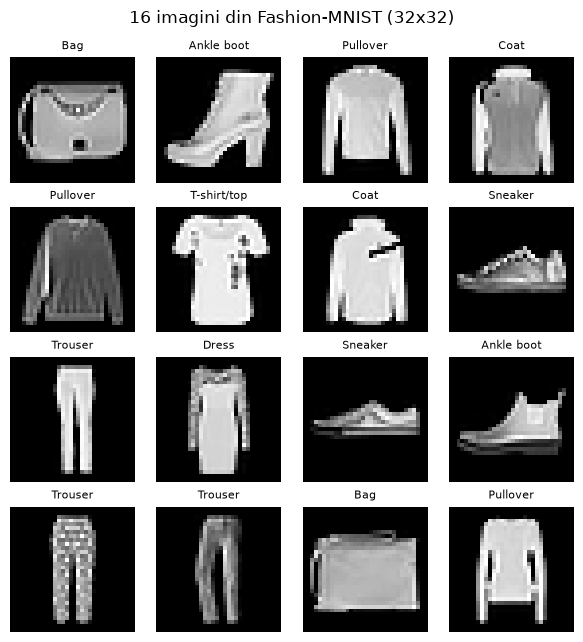

In [3]:
xb, yb = next(iter(incarcator))

fig, axe = plt.subplots(4, 4, figsize=(6, 6.5))
for i, ax in enumerate(axe.flat):
    ax.imshow(((xb[i, 0] + 1) / 2).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(clase[int(yb[i])], fontsize=8)
    ax.axis("off")
fig.suptitle("16 imagini din Fashion-MNIST (32x32)")
plt.tight_layout()
plt.savefig(FOLDER / "s1_date.png", dpi=120)
plt.show()

**Observație.** Datele au forma (60000, 1, 32, 32), iar valorile sunt în [−1, 1]. Verificarea arată că transformarea vectorizată dă exact același rezultat ca `transforms.Compose`. În grilă se vede bordura neagră de 2 pixeli adăugată de `Pad(2)`.

## Sarcina 2. Procesul direct

Procesul direct adaugă puțin câte puțin zgomot peste o imagine, până când aceasta devine zgomot pur. Cât zgomot se adaugă la pasul $t$ este dat de $\beta_t$. Notez $\alpha_t = 1-\beta_t$ și $\bar\alpha_t = \alpha_1\alpha_2\cdots\alpha_t$ (calculat cu `torch.cumprod`).

Imaginea zgomotoasă de la orice pas se obține direct, într-un singur calcul:

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\qquad \varepsilon\sim\mathcal N(0,I)$$

Programele de zgomot comparate:
* **liniar**: $\beta$ crește uniform de la 0,0001 la 0,02;
* **cosinus**: $f(t)=\cos^2\!\left(\frac{t/T+s}{1+s}\cdot\frac{\pi}{2}\right)$, $\bar\alpha_t=f(t)/f(0)$, $\beta_t = 1-\bar\alpha_t/\bar\alpha_{t-1}$, limitat la 0,999, cu $s=0{,}008$.

In [4]:
def beta_liniar(T):
    return torch.linspace(1e-4, 0.02, T)

def beta_cosinus(T, s=0.008):
    t = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos((t / T + s) / (1 + s) * math.pi / 2) ** 2
    ab = f / f[0]
    return (1 - ab[1:] / ab[:-1]).clamp(max=0.999).float()

def construieste_program(betas):
    alphas = 1 - betas
    alpha_bar = torch.cumprod(alphas, dim=0)
    return {"beta": betas.to(device), "alpha": alphas.to(device), "alpha_bar": alpha_bar.to(device)}

prog_lin = construieste_program(beta_liniar(T))
prog_cos = construieste_program(beta_cosinus(T))

def q_sample(x0, t, eps, prog):
    # x0: imagini (B,1,32,32); t: pașii (B,); eps: zgomot de aceeași formă cu x0
    ab = prog["alpha_bar"][t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

for nume, p in [("liniar", prog_lin), ("cosinus", prog_cos)]:
    print(f"{nume:8s}: beta_min={p['beta'].min():.6f}, beta_max={p['beta'].max():.4f}, "
          f"alpha_bar[999]={p['alpha_bar'][-1]:.2e}")

liniar  : beta_min=0.000100, beta_max=0.0200, alpha_bar[999]=4.04e-05
cosinus : beta_min=0.000041, beta_max=0.9990, alpha_bar[999]=2.43e-09


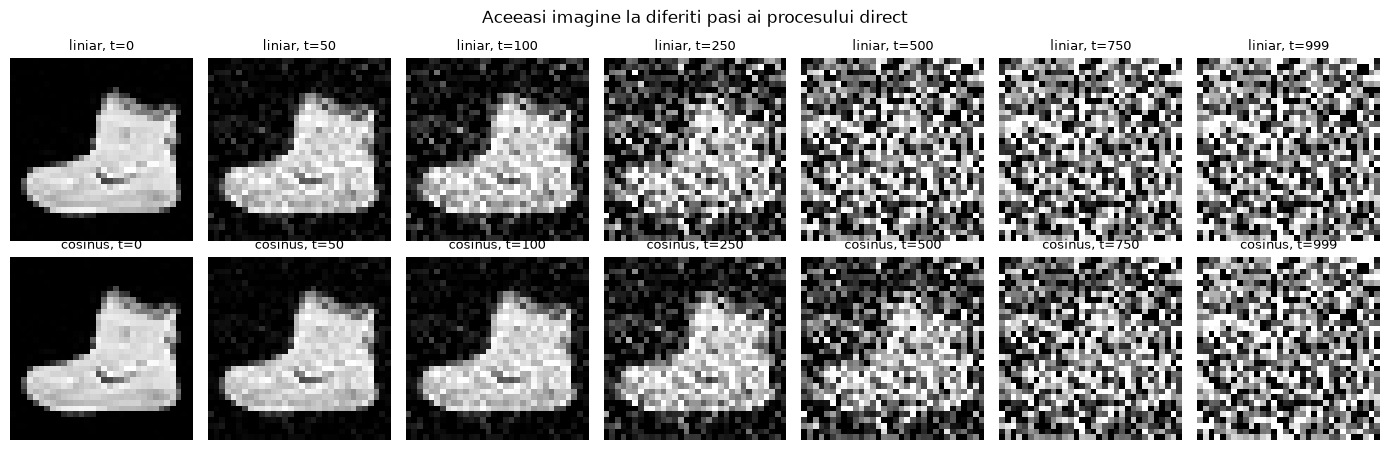

In [5]:
pasi = [0, 50, 100, 250, 500, 750, 999]
x0 = X[:1].to(device)
eps = torch.randn(x0.shape, generator=torch.Generator().manual_seed(0)).to(device)

fig, axe = plt.subplots(2, len(pasi), figsize=(14, 4.6))
for r, (nume, p) in enumerate([("liniar", prog_lin), ("cosinus", prog_cos)]):
    for k, t in enumerate(pasi):
        xt = q_sample(x0, torch.tensor([t], device=device), eps, p)
        axe[r, k].imshow(((xt[0, 0].clamp(-1, 1) + 1) / 2).cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        axe[r, k].set_title(f"{nume}, t={t}", fontsize=9)
        axe[r, k].axis("off")
fig.suptitle("Aceeasi imagine la diferiti pasi ai procesului direct")
plt.tight_layout()
plt.savefig(FOLDER / "s2_proces_direct.png", dpi=120)
plt.show()

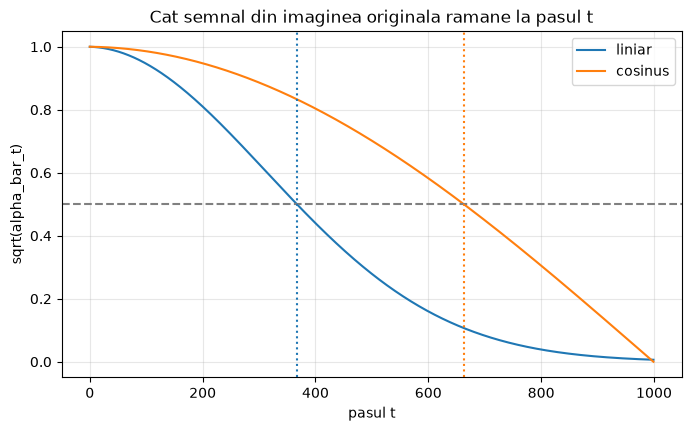

sqrt(alpha_bar) scade sub 0.5 la pasul:
  liniar : 368
  cosinus: 664


In [6]:
radical_lin = prog_lin["alpha_bar"].sqrt().cpu()
radical_cos = prog_cos["alpha_bar"].sqrt().cpu()
t_lin = int(torch.nonzero(radical_lin < 0.5)[0])
t_cos = int(torch.nonzero(radical_cos < 0.5)[0])

plt.figure(figsize=(8, 4.5))
plt.plot(radical_lin, label="liniar")
plt.plot(radical_cos, label="cosinus")
plt.axhline(0.5, ls="--", color="gray")
plt.axvline(t_lin, ls=":", color="C0"); plt.axvline(t_cos, ls=":", color="C1")
plt.xlabel("pasul t"); plt.ylabel("sqrt(alpha_bar_t)")
plt.title("Cat semnal din imaginea originala ramane la pasul t")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(FOLDER / "s2_sqrt_alpha_bar.png", dpi=120)
plt.show()

print("sqrt(alpha_bar) scade sub 0.5 la pasul:")
print("  liniar :", t_lin)
print("  cosinus:", t_cos)

**Observație.** La programul liniar, $\sqrt{\bar\alpha_t}$ coboară sub 0,5 la pasul **368**. La programul cosinus coboară abia la pasul **664**. Valorile sunt calculate în celula de mai sus.

Programul liniar distruge imaginea repede: de pe la jumătatea procesului ($t=500$) obiectul aproape nu se mai vede, iar ultimii câțiva sute de pași sunt practic zgomot. Programul cosinus scade semnalul mai uniform, așa că pașii cu nivel mediu de zgomot ocupă o parte mai mare din procesul de difuzie. De la pașii aceștia învață rețeaua cel mai mult.

## Sarcina 3. Rețeaua U-Net

Rețeaua primește o imagine zgomotoasă $x_t$ și pasul $t$ și trebuie să ghicească zgomotul $\varepsilon$ din ea. Codul este cel dat în PDF. Am adăugat comentarii la cele trei elemente cerute:
* **încorporarea pasului t:** $t$ devine un vector de sinusuri și cosinusuri, care se adaugă în fiecare bloc;
* **conexiunile reziduale:** fiecare bloc întoarce `h + skip(x)`;
* **conexiunile skip:** ieșirile de pe drumul de coborâre se lipesc (concatenează) la nivelul de aceeași mărime de pe drumul de urcare.

In [7]:
def time_embedding(t, dim=128):
    # ÎNCORPORAREA PASULUI t: fiecare pas devine un vector de dim valori (sin și cos la frecvențe diferite)
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)


class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, t_dim=128):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, c_out)          # aici intră pasul t în bloc
        self.norm2 = nn.GroupNorm(8, c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, temb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(temb)[:, :, None, None]    # pasul t se adună pe fiecare canal
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)                        # CONEXIUNE REZIDUALĂ


class UNet(nn.Module):
    def __init__(self, ch=(32, 64, 128), t_dim=128):
        super().__init__()
        self.t_mlp = nn.Sequential(nn.Linear(t_dim, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))
        self.inp = nn.Conv2d(1, ch[0], 3, padding=1)
        self.down1 = ResBlock(ch[0], ch[0])
        self.down2 = ResBlock(ch[0], ch[1])
        self.down3 = ResBlock(ch[1], ch[2])
        self.mid = ResBlock(ch[2], ch[2])
        self.up3 = ResBlock(2 * ch[2], ch[1])
        self.up2 = ResBlock(2 * ch[1], ch[0])
        self.up1 = ResBlock(2 * ch[0], ch[0])
        self.out = nn.Conv2d(ch[0], 1, 1)

    def forward(self, x, t):
        temb = self.t_mlp(time_embedding(t))                   # ÎNCORPORAREA PASULUI t
        x = self.inp(x)
        s1 = self.down1(x, temb)                               # 32x32
        s2 = self.down2(F.avg_pool2d(s1, 2), temb)             # 16x16
        s3 = self.down3(F.avg_pool2d(s2, 2), temb)             # 8x8
        h = self.mid(F.avg_pool2d(s3, 2), temb)                # 4x4
        up = lambda z: F.interpolate(z, scale_factor=2)
        h = self.up3(torch.cat([up(h), s3], dim=1), temb)      # CONEXIUNE SKIP cu s3
        h = self.up2(torch.cat([up(h), s2], dim=1), temb)      # CONEXIUNE SKIP cu s2
        h = self.up1(torch.cat([up(h), s1], dim=1), temb)      # CONEXIUNE SKIP cu s1
        return self.out(h)                                     # zgomotul prezis

In [8]:
retea = UNet()
iesire = retea(torch.randn(8, 1, 32, 32), torch.randint(0, 1000, (8,)))
print("Forma ieșirii:", tuple(iesire.shape))
assert iesire.shape == (8, 1, 32, 32)

nr_param = sum(p.numel() for p in retea.parameters())
print(f"Număr de parametri: {nr_param:,}")

Forma ieșirii: (8, 1, 32, 32)
Număr de parametri: 979,585


**Observație.** Ieșirea are aceeași formă ca intrarea, (8, 1, 32, 32): rețeaua întoarce câte o „hartă de zgomot” pentru fiecare imagine. Modelul are **979 585** de parametri, adică aproximativ 1 milion, cum indică PDF-ul.

## Sarcina 4. Antrenarea cu programul liniar

La fiecare lot de imagini:
1. aleg pentru fiecare imagine un pas $t$ aleator între 0 și 999;
2. generez zgomotul $\varepsilon$;
3. calculez $x_t$ cu `q_sample`;
4. rețeaua prezice zgomotul, iar eroarea este $L = \text{media}\,\lVert\varepsilon-\varepsilon_\theta(x_t,t)\rVert^2$ (`F.mse_loss`).

Setări: Adam, rata de învățare 0,0002, loturi de 128, 15 epoci, seed 42. Scriu antrenarea ca funcție, pentru că o refolosesc la Sarcina 7 cu programul cosinus. Dacă modelul a fost deja antrenat și salvat, funcția îl încarcă de pe disc.

In [9]:
def antreneaza(prog, nume, ch=(32, 64, 128)):
    fisier = FOLDER / f"model_{nume}.pt"
    model = UNet(ch=ch).to(device)
    if fisier.exists():                               # modelul există deja: nu îl mai antrenez
        salvat = torch.load(fisier, map_location=device)
        model.load_state_dict(salvat["model"])
        print(f"Model '{nume}' încărcat din {fisier}")
        return model, salvat["pierderi"], salvat["timp"]

    fixeaza_seed(42)
    model = UNet(ch=ch).to(device)                    # aceeași inițializare pentru orice program
    optim = torch.optim.Adam(model.parameters(), lr=LR)
    loader = DataLoader(TensorDataset(X), batch_size=BATCH, shuffle=True,
                        generator=torch.Generator().manual_seed(42))
    pierderi = []
    start = time.perf_counter()
    for epoca in range(EPOCI):
        model.train()
        suma, n = 0.0, 0
        for (x0,) in loader:
            x0 = x0.to(device)
            t = torch.randint(0, T, (x0.shape[0],), device=device)
            eps = torch.randn_like(x0)
            xt = q_sample(x0, t, eps, prog)
            loss = F.mse_loss(model(xt, t), eps)
            optim.zero_grad()
            loss.backward()
            optim.step()
            suma += loss.item() * x0.shape[0]
            n += x0.shape[0]
        pierderi.append(suma / n)
        print(f"[{nume}] epoca {epoca + 1:2d}/{EPOCI}: pierdere = {pierderi[-1]:.4f}  "
              f"({(time.perf_counter() - start) / 60:.1f} min de la început)")
    durata = time.perf_counter() - start
    torch.save({"model": model.state_dict(), "pierderi": pierderi, "timp": durata}, fisier)
    print(f"Model salvat în {fisier} (antrenare: {durata / 60:.1f} min)")
    return model, pierderi, durata

model_lin, pierderi_lin, timp_lin = antreneaza(prog_lin, "liniar")

[liniar] epoca  1/15: pierdere = 0.0931  (4.6 min de la început)
[liniar] epoca  2/15: pierdere = 0.0476  (9.2 min de la început)
[liniar] epoca  3/15: pierdere = 0.0422  (14.0 min de la început)
[liniar] epoca  4/15: pierdere = 0.0397  (18.9 min de la început)
[liniar] epoca  5/15: pierdere = 0.0380  (23.7 min de la început)
[liniar] epoca  6/15: pierdere = 0.0365  (28.4 min de la început)
[liniar] epoca  7/15: pierdere = 0.0364  (33.2 min de la început)
[liniar] epoca  8/15: pierdere = 0.0349  (38.4 min de la început)
[liniar] epoca  9/15: pierdere = 0.0349  (43.8 min de la început)
[liniar] epoca 10/15: pierdere = 0.0342  (48.9 min de la început)
[liniar] epoca 11/15: pierdere = 0.0339  (53.9 min de la început)
[liniar] epoca 12/15: pierdere = 0.0336  (59.0 min de la început)
[liniar] epoca 13/15: pierdere = 0.0330  (64.3 min de la început)
[liniar] epoca 14/15: pierdere = 0.0328  (69.2 min de la început)
[liniar] epoca 15/15: pierdere = 0.0327  (74.3 min de la început)
Model salvat

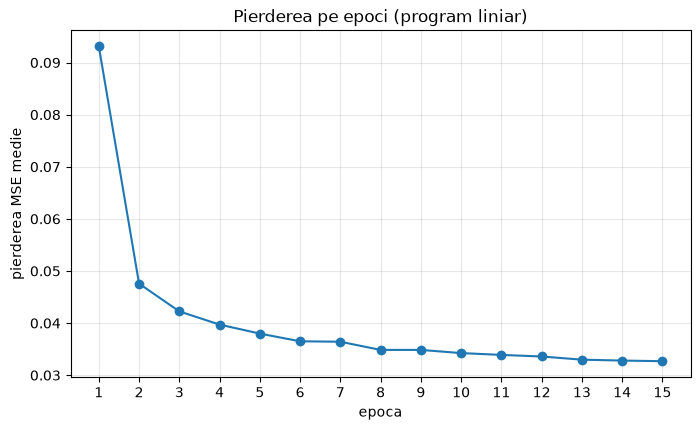

Pierderea în prima și în ultima epocă: 0.0931 -> 0.0327


In [11]:
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, EPOCI + 1), pierderi_lin, "o-")
plt.xlabel("epoca"); plt.ylabel("pierderea MSE medie")
plt.title("Pierderea pe epoci (program liniar)")
plt.xticks(range(1, EPOCI + 1)); plt.grid(alpha=0.3)
plt.savefig(FOLDER / "s4_pierdere.png", dpi=120)
plt.show()
print("Pierderea în prima și în ultima epocă:", round(pierderi_lin[0], 4), "->", round(pierderi_lin[-1], 4))

**Ce urmăresc în grafic.** Pierderea trebuie să scadă repede în primele epoci și apoi să se stabilizeze. Nu ajunge niciodată la zero: la pașii cu zgomot mic, zgomotul este aproape imposibil de separat exact de imagine. Valorile concrete de la prima și ultima epocă sunt afișate mai sus.

## Sarcina 5. Generarea DDPM

Generarea pornește de la zgomot pur și parcurge pașii înapoi, $t = 999, \dots, 0$. La fiecare pas, rețeaua estimează zgomotul, iar o parte din el este eliminată:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon_\theta(x_t,t)\right) + \sigma_t z,\qquad \sigma_t^2=\beta_t$$

La ultimul pas nu se mai adaugă zgomot ($z = 0$). Generez 64 de imagini și păstrez 8 stări intermediare ale primei imagini.

DDPM, 1000 de pași, 64 de imagini: 76.9 s


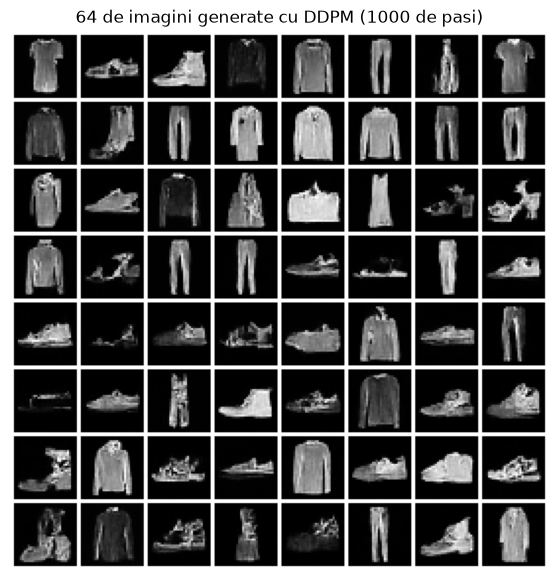

In [12]:
@torch.no_grad()
def genereaza_ddpm(model, prog, zgomot, pasi_salvati=()):
    model.eval()
    x = zgomot.clone()
    stari = []
    for t in reversed(range(T)):
        if t in pasi_salvati:
            stari.append((t, x[0].cpu()))
        tt = torch.full((x.shape[0],), t, device=device, dtype=torch.long)
        eps_prezis = model(x, tt)
        beta, alpha, ab = prog["beta"][t], prog["alpha"][t], prog["alpha_bar"][t]
        x = (x - beta / torch.sqrt(1 - ab) * eps_prezis) / torch.sqrt(alpha)
        if t > 0:
            x = x + torch.sqrt(beta) * torch.randn_like(x)
    stari.append(("final", x[0].cpu()))
    return x.clamp(-1, 1).cpu(), stari

# același zgomot de pornire pentru Sarcinile 5, 6 și 7
zgomot_initial = torch.randn(64, 1, 32, 32, generator=torch.Generator().manual_seed(42)).to(device)

def arata_grila(imagini, titlu, fisier):
    g = make_grid((imagini + 1) / 2, nrow=8, padding=2, pad_value=1)
    plt.figure(figsize=(7, 7))
    plt.imshow(g.permute(1, 2, 0).numpy())
    plt.title(titlu); plt.axis("off")
    plt.savefig(FOLDER / fisier, dpi=120)
    plt.show()

fixeaza_seed(42)
pasi_stari = [999, 850, 700, 550, 400, 250, 100]
sync(); t0 = time.perf_counter()
imagini_ddpm, stari = genereaza_ddpm(model_lin, prog_lin, zgomot_initial, pasi_stari)
sync(); timp_ddpm = time.perf_counter() - t0
print(f"DDPM, 1000 de pași, 64 de imagini: {timp_ddpm:.1f} s")
arata_grila(imagini_ddpm, "64 de imagini generate cu DDPM (1000 de pasi)", "s5_ddpm.png")

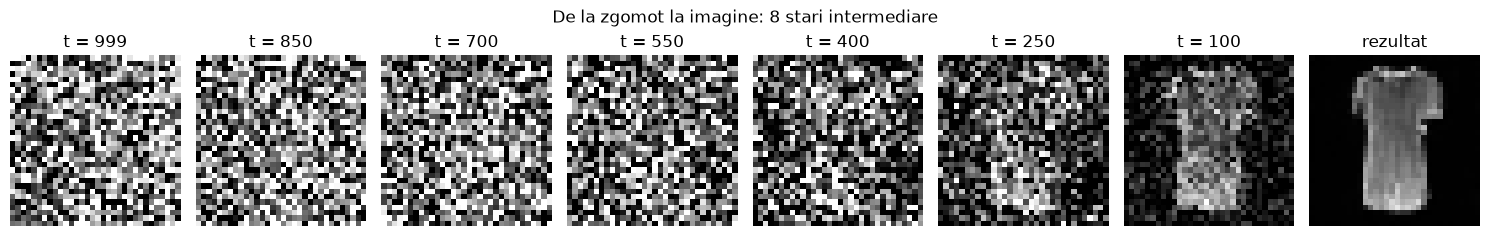

In [13]:
fig, axe = plt.subplots(1, 8, figsize=(15, 2.4))
for ax, (t, img) in zip(axe, stari):
    ax.imshow(((img[0].clamp(-1, 1) + 1) / 2).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {t}" if t != "final" else "rezultat")
    ax.axis("off")
fig.suptitle("De la zgomot la imagine: 8 stari intermediare")
plt.tight_layout()
plt.savefig(FOLDER / "s5_stari.png", dpi=120)
plt.show()

**Ce se vede.** Șirul de stări arată cum apare imaginea din zgomot: forma generală a obiectului se conturează pe la jumătatea traseului, iar detaliile apar abia în ultimii pași. Calitatea grilei de 64 de imagini o apreciez vizual în tabelul de la Sarcina 6.

## Sarcina 6. Mai puțini pași cu DDIM

DDIM folosește aceeași rețea, dar un drum **determinist** (fără zgomot nou), care poate sări peste pași. Pentru doi pași consecutivi din șirul rar $t \to t'$:

$$\hat x_0 = \frac{x_t-\sqrt{1-\bar\alpha_t}\,\varepsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}},\qquad x_{t'}=\sqrt{\bar\alpha_{t'}}\,\hat x_0+\sqrt{1-\bar\alpha_{t'}}\,\varepsilon_\theta(x_t,t)$$

La ultimul pas rezultatul este $\hat x_0$. Șirul de pași este `torch.linspace(999, 0, n)`, rotunjit la numere întregi.

**Notă:** limitez $\hat x_0$ la intervalul [−1, 1], intervalul imaginilor. La primii pași $\sqrt{\bar\alpha_t}$ este foarte mic (la cosinus, aproximativ 0,00005), iar împărțirea la el ar amplifica enorm orice eroare a rețelei. Aceeași limitare o face și `DDIMScheduler` din biblioteca diffusers (`clip_sample=True`).

In [14]:
@torch.no_grad()
def genereaza_ddim(model, prog, zgomot, n_pasi):
    model.eval()
    ab = prog["alpha_bar"]
    pasi = torch.linspace(T - 1, 0, n_pasi).round().long().tolist()
    x = zgomot.clone()
    for i, t in enumerate(pasi):
        tt = torch.full((x.shape[0],), t, device=device, dtype=torch.long)
        eps_prezis = model(x, tt)
        x0_estimat = ((x - torch.sqrt(1 - ab[t]) * eps_prezis) / torch.sqrt(ab[t])).clamp(-1, 1)
        if i == len(pasi) - 1:
            x = x0_estimat
        else:
            t2 = pasi[i + 1]
            x = torch.sqrt(ab[t2]) * x0_estimat + torch.sqrt(1 - ab[t2]) * eps_prezis
    return x.clamp(-1, 1).cpu()

rezultate_ddim = {}
for n in [1000, 200, 50, 20, 10]:
    sync(); t0 = time.perf_counter()
    img = genereaza_ddim(model_lin, prog_lin, zgomot_initial, n)
    sync(); durata = time.perf_counter() - t0
    rezultate_ddim[n] = (img, durata)
    print(f"DDIM cu {n:4d} pași: {durata:6.2f} s")

DDIM cu 1000 pași:  88.36 s
DDIM cu  200 pași:  21.67 s
DDIM cu   50 pași:   4.30 s
DDIM cu   20 pași:   1.81 s
DDIM cu   10 pași:   0.87 s


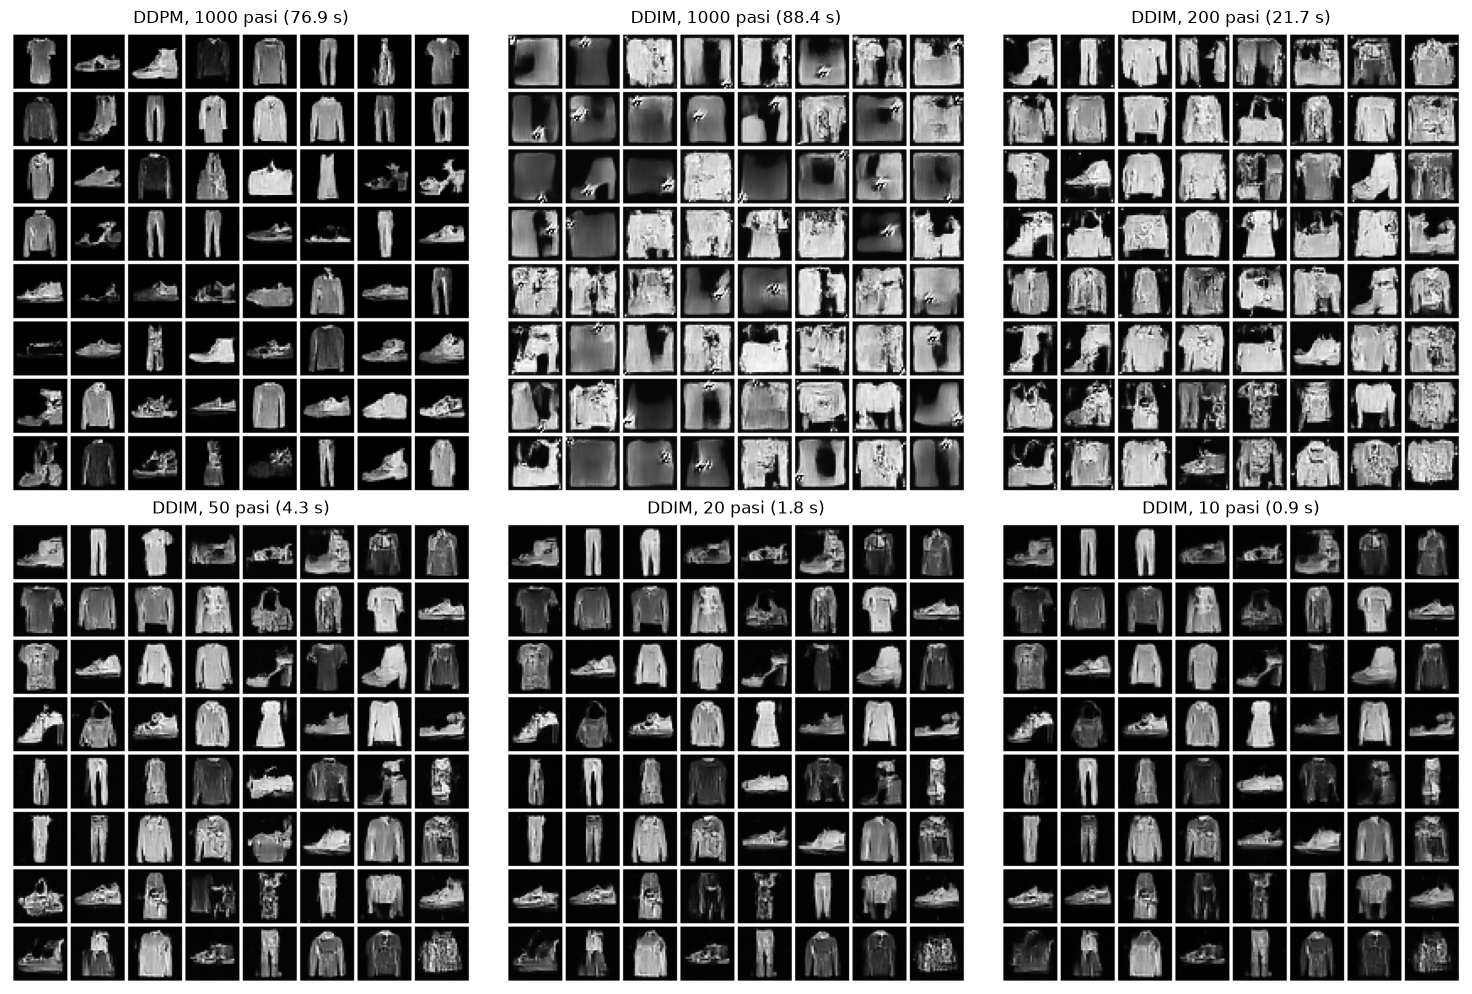

In [15]:
fig, axe = plt.subplots(2, 3, figsize=(15, 10))
panouri = [("DDPM, 1000 pasi", imagini_ddpm, timp_ddpm)] + \
          [(f"DDIM, {n} pasi", *rezultate_ddim[n]) for n in [1000, 200, 50, 20, 10]]
for ax, (titlu, img, durata) in zip(axe.flat, panouri):
    g = make_grid((img + 1) / 2, nrow=8, padding=2, pad_value=1)
    ax.imshow(g.permute(1, 2, 0).numpy())
    ax.set_title(f"{titlu} ({durata:.1f} s)")
    ax.axis("off")
plt.tight_layout()
plt.savefig(FOLDER / "s6_ddim.png", dpi=110)
plt.show()

### Tabelul DDPM / DDIM

Timpii sunt cei măsurați mai sus. **Calitatea vizuală (1–5) și observațiile le completez eu în dicționarele de mai jos, după ce mă uit la grile.** Nu se pot calcula automat.

Scara folosită: 5 = obiecte clare, ca în date; 4 = bune, cu mici defecte; 3 = recognoscibile, dar neclare; 2 = forme vagi; 1 = zgomot.

In [16]:
calitate = {"DDPM-1000": None, "DDIM-1000": None, "DDIM-200": None,
            "DDIM-50": None, "DDIM-20": None, "DDIM-10": None}
observatii = {"DDPM-1000": "", "DDIM-1000": "", "DDIM-200": "",
              "DDIM-50": "", "DDIM-20": "", "DDIM-10": ""}

randuri = [("DDPM", 1000, timp_ddpm)] + [("DDIM", n, rezultate_ddim[n][1]) for n in [1000, 200, 50, 20, 10]]
tabel6 = pd.DataFrame([{
    "Metodă": m, "Pași": n,
    "Timp pentru 64 de imagini (s)": round(d, 2),
    "Calitate vizuală (1–5)": calitate[f"{m}-{n}"] if calitate[f"{m}-{n}"] is not None else "de completat",
    "Observații": observatii[f"{m}-{n}"],
} for m, n, d in randuri])
tabel6.to_csv(FOLDER / "tabel_sarcina6.csv", index=False)
tabel6

,Metodă,Pași,Timp pentru 64 de imagini (s),Calitate vizuală (1–5),Observații
0,DDPM,1000,76.92,de completat,
1,DDIM,1000,88.36,de completat,
2,DDIM,200,21.67,de completat,
3,DDIM,50,4.30,de completat,
4,DDIM,20,1.81,de completat,
5,DDIM,10,0.87,de completat,


**Cum interpretez tabelul.** Timpul scade aproape proporțional cu numărul de pași: fiecare pas înseamnă o trecere prin rețea. Întrebarea este de la ce număr de pași calitatea începe să scadă vizibil. În mod obișnuit DDIM rămâne aproape de DDPM până la câteva zeci de pași, iar la 10 pași imaginile devin mai netede și pierd detalii. Concluzia pentru modelul meu se ia din coloana de calitate, completată după grile.

## Sarcina 7. Liniar vs. cosinus

Antrenez al doilea model **identic**: aceeași rețea, aceeași inițializare (seed 42), aceleași setări, 15 epoci. Diferă doar programul de zgomot, care acum este cosinus. Apoi generez cu ambele modele, cu DDIM la 50 și la 20 de pași, din același zgomot de pornire.

[cosinus] epoca  1/15: pierdere = 0.1412  (4.5 min de la început)
[cosinus] epoca  2/15: pierdere = 0.0813  (9.3 min de la început)
[cosinus] epoca  3/15: pierdere = 0.0736  (14.2 min de la început)
[cosinus] epoca  4/15: pierdere = 0.0698  (19.3 min de la început)
[cosinus] epoca  5/15: pierdere = 0.0671  (24.3 min de la început)
[cosinus] epoca  6/15: pierdere = 0.0650  (29.6 min de la început)
[cosinus] epoca  7/15: pierdere = 0.0648  (34.9 min de la început)
[cosinus] epoca  8/15: pierdere = 0.0626  (40.0 min de la început)
[cosinus] epoca  9/15: pierdere = 0.0623  (45.8 min de la început)
[cosinus] epoca 10/15: pierdere = 0.0615  (50.8 min de la început)
[cosinus] epoca 11/15: pierdere = 0.0608  (56.2 min de la început)
[cosinus] epoca 12/15: pierdere = 0.0603  (61.0 min de la început)
[cosinus] epoca 13/15: pierdere = 0.0595  (66.0 min de la început)
[cosinus] epoca 14/15: pierdere = 0.0593  (71.0 min de la început)
[cosinus] epoca 15/15: pierdere = 0.0587  (76.1 min de la începu

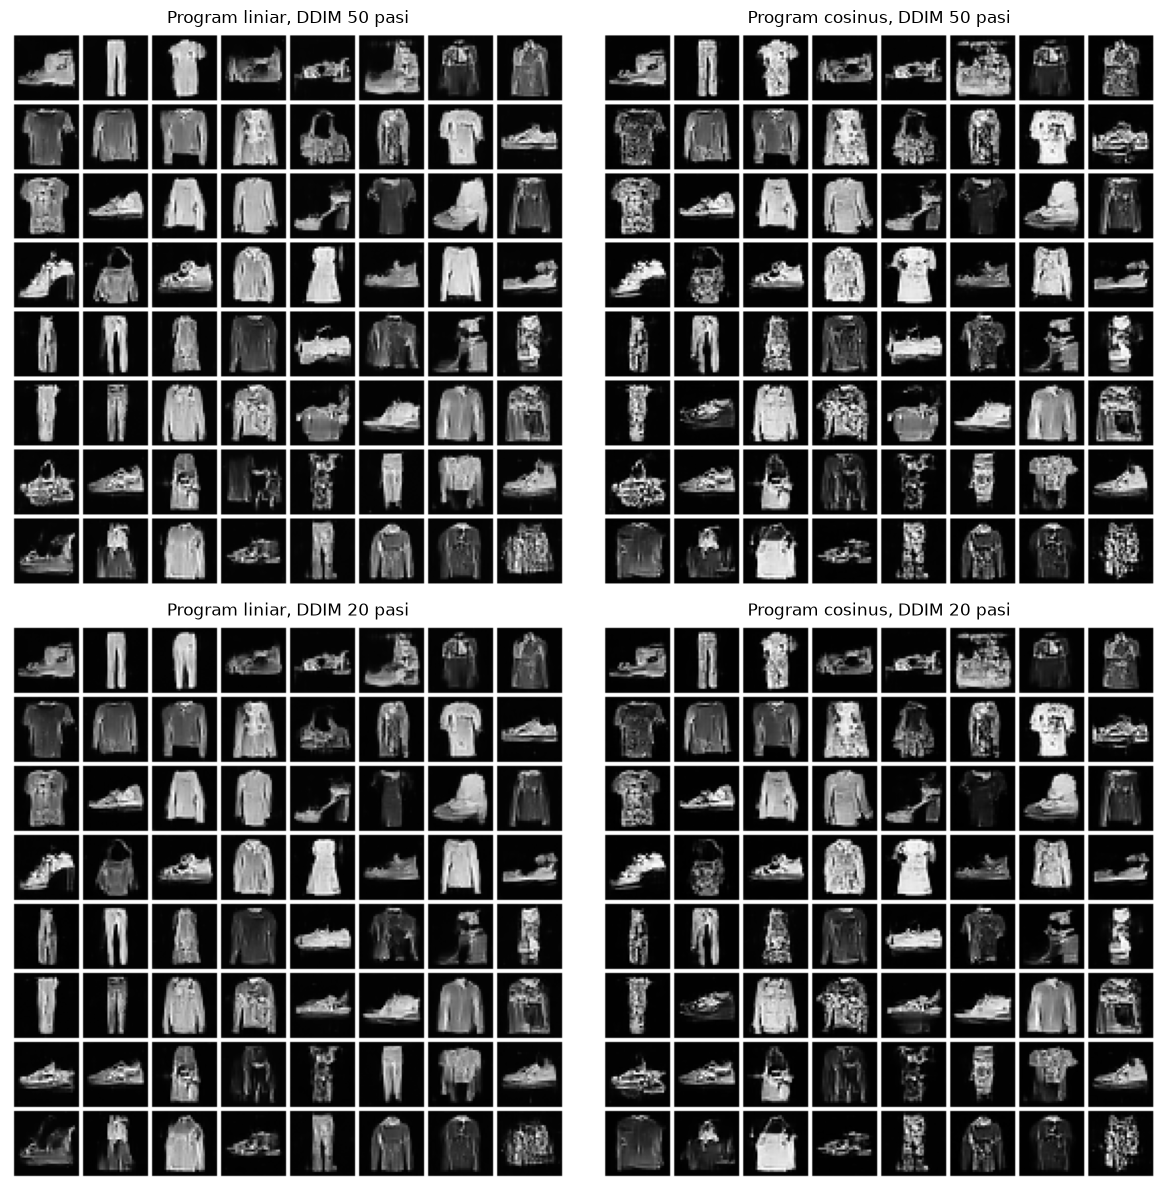

In [17]:
model_cos, pierderi_cos, timp_cos = antreneaza(prog_cos, "cosinus")

comparatie = {}
for n in [50, 20]:
    comparatie[("liniar", n)] = rezultate_ddim[n][0]          # deja generate la Sarcina 6, același zgomot
    comparatie[("cosinus", n)] = genereaza_ddim(model_cos, prog_cos, zgomot_initial, n)

fig, axe = plt.subplots(2, 2, figsize=(12, 12))
for r, n in enumerate([50, 20]):
    for c, nume in enumerate(["liniar", "cosinus"]):
        g = make_grid((comparatie[(nume, n)] + 1) / 2, nrow=8, padding=2, pad_value=1)
        axe[r, c].imshow(g.permute(1, 2, 0).numpy())
        axe[r, c].set_title(f"Program {nume}, DDIM {n} pasi")
        axe[r, c].axis("off")
plt.tight_layout()
plt.savefig(FOLDER / "s7_comparatie.png", dpi=110)
plt.show()

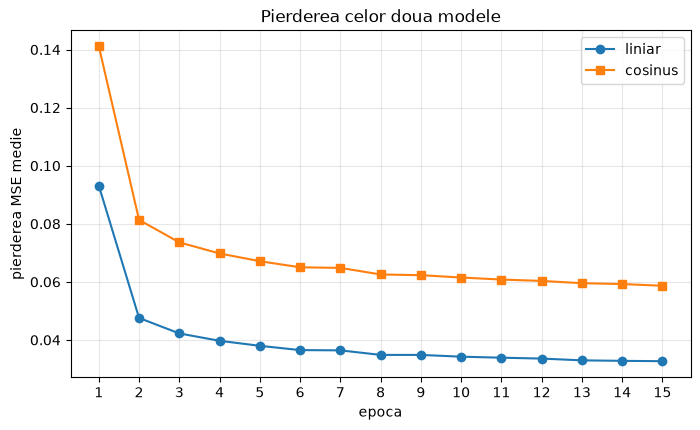

,Program,DDIM pași,Calitate vizuală (1–5)
0,liniar,50,de completat
1,cosinus,50,de completat
2,liniar,20,de completat
3,cosinus,20,de completat


In [18]:
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, EPOCI + 1), pierderi_lin, "o-", label="liniar")
plt.plot(range(1, EPOCI + 1), pierderi_cos, "s-", label="cosinus")
plt.xlabel("epoca"); plt.ylabel("pierderea MSE medie")
plt.title("Pierderea celor doua modele")
plt.xticks(range(1, EPOCI + 1)); plt.legend(); plt.grid(alpha=0.3)
plt.savefig(FOLDER / "s7_pierderi.png", dpi=120)
plt.show()

calitate7 = {("liniar", 50): None, ("cosinus", 50): None, ("liniar", 20): None, ("cosinus", 20): None}
tabel7 = pd.DataFrame([{"Program": p, "DDIM pași": n,
                        "Calitate vizuală (1–5)": calitate7[(p, n)] if calitate7[(p, n)] is not None else "de completat"}
                       for (p, n) in calitate7])
tabel7

**De ce pierderile nu se pot compara direct.** Pierderea este o medie peste pași $t$ aleși la întâmplare, iar dificultatea depinde de nivelul de zgomot. Când imaginea e aproape zgomot pur, rețeaua are o sarcină ușoară: zgomotul este practic chiar intrarea. Când zgomotul e foarte slab, sarcina e grea. Cele două programe împart diferit cei 1000 de pași între nivelurile de zgomot. La liniar, aproximativ un sfert dintre pași sunt aproape zgomot pur, deci „ușori”. La cosinus sunt mult mai puțini. Așadar fiecare model este mediat pe o altă problemă, iar o pierdere mai mică **nu** înseamnă un model mai bun. Modelele le compar după imaginile generate din același zgomot.

### Bonus: rețea mai mică, `UNet(ch=(16, 32, 64))`

Opțional: setați `FA_BONUS = True` (înseamnă încă 15 epoci de antrenare). Compar numărul de parametri, timpul de antrenare și imaginile generate cu DDIM la 50 de pași.

[liniar_mic] epoca  1/15: pierdere = 0.1472  (2.5 min de la început)
[liniar_mic] epoca  2/15: pierdere = 0.0584  (6.8 min de la început)
[liniar_mic] epoca  3/15: pierdere = 0.0501  (12.6 min de la început)
[liniar_mic] epoca  4/15: pierdere = 0.0462  (18.0 min de la început)
[liniar_mic] epoca  5/15: pierdere = 0.0437  (23.0 min de la început)
[liniar_mic] epoca  6/15: pierdere = 0.0419  (28.2 min de la început)
[liniar_mic] epoca  7/15: pierdere = 0.0408  (33.3 min de la început)
[liniar_mic] epoca  8/15: pierdere = 0.0393  (38.2 min de la început)
[liniar_mic] epoca  9/15: pierdere = 0.0390  (43.1 min de la început)
[liniar_mic] epoca 10/15: pierdere = 0.0380  (48.4 min de la început)
[liniar_mic] epoca 11/15: pierdere = 0.0379  (53.9 min de la început)
[liniar_mic] epoca 12/15: pierdere = 0.0373  (59.5 min de la început)
[liniar_mic] epoca 13/15: pierdere = 0.0369  (64.3 min de la început)
[liniar_mic] epoca 14/15: pierdere = 0.0366  (105.3 min de la început)
[liniar_mic] epoca 15

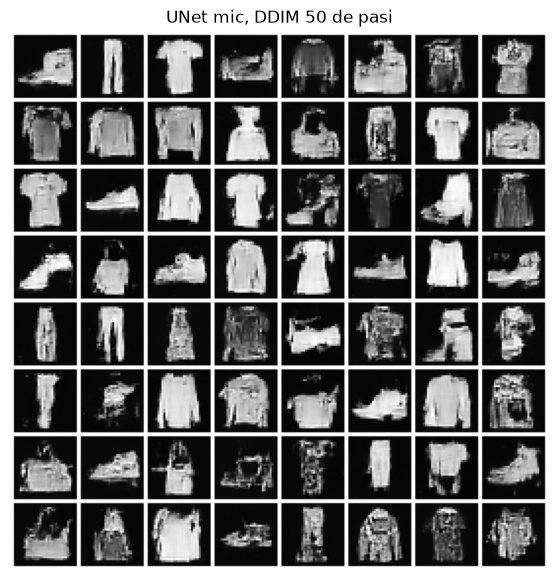

In [21]:
FA_BONUS = True

if FA_BONUS:
    model_mic, pierderi_mic, timp_mic = antreneaza(prog_lin, "liniar_mic", ch=(16, 32, 64))
    img_mic = genereaza_ddim(model_mic, prog_lin, zgomot_initial, 50)
    print(pd.DataFrame([
        {"Rețea": "UNet(32, 64, 128)", "Parametri": sum(p.numel() for p in model_lin.parameters()),
         "Antrenare (min)": round(timp_lin / 60, 1), "Pierdere finală": round(pierderi_lin[-1], 4)},
        {"Rețea": "UNet(16, 32, 64)", "Parametri": sum(p.numel() for p in model_mic.parameters()),
         "Antrenare (min)": round(timp_mic / 60, 1), "Pierdere finală": round(pierderi_mic[-1], 4)},
    ]).to_string(index=False))
    arata_grila(img_mic, "UNet mic, DDIM 50 de pasi", "bonus_unet_mic.png")
else:
    print("Bonusul nu a fost rulat.")

## Întrebări de control

**1. De ce procesul direct nu are parametri învățați? Ce rol are în antrenare?**
Procesul direct este stabilit de mine dinainte, prin programul $\beta_t$: la fiecare pas se adaugă zgomot gaussian într-o cantitate cunoscută. Nu are nimic de învățat, pentru că rolul lui este doar să strice imaginile într-un mod controlat. În antrenare el produce exemplele: din orice imagine reală obțin perechi (imagine zgomotoasă $x_t$, zgomotul $\varepsilon$ adăugat), iar rețeaua învață să recupereze $\varepsilon$.

**2. De ce putem sări direct la pasul t, fără să parcurgem pașii anteriori?**
Adunarea succesivă de zgomote gaussiene independente dă tot un zgomot gaussian. Aplicat de $t$ ori, procesul se reduce la o singură formulă: $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\,\varepsilon$. De aceea `q_sample` obține direct imaginea de la orice pas, iar la antrenare pot alege $t$ la întâmplare pentru fiecare imagine.

**3. De ce rețeaua primește și numărul pasului t? Ce s-ar întâmpla fără el?**
Cât zgomot trebuie eliminat depinde de $t$: la $t$ mic e puțin zgomot, la $t$ mare imaginea e aproape numai zgomot. Fără $t$, rețeaua ar trebui să ghicească nivelul de zgomot din imagine și ar ajunge la o medie: ar elimina prea puțin zgomot la pașii mari și prea mult la cei mici. Imaginile generate ar fi neclare sau cu artefacte.

**4. De ce generarea e mult mai lentă decât un pas de antrenare?**
Un pas de antrenare înseamnă o singură trecere prin rețea, la un $t$ ales la întâmplare. Generarea DDPM are nevoie de 1000 de treceri, una după alta, pentru că fiecare pas pornește de la rezultatul pasului anterior. Pașii nu se pot face în paralel.

**5. Ce diferență vedeți între programul liniar și cel cosinus la Sarcinile 2 și 7? Cum o explicați?**
La Sarcina 2, programul liniar distruge imaginea mult mai repede: $\sqrt{\bar\alpha_t}<0{,}5$ de la pasul 368, față de 664 la cosinus. La liniar, mulți pași de la sfârșit sunt aproape zgomot pur și aduc puțină informație. Programul cosinus împarte zgomotul mai uniform și lasă mai mulți pași la niveluri medii de zgomot, unde se formează conturul obiectelor. La Sarcina 7, diferența dintre imagini se vede în grilele comparative și în notele din tabel.

**6. Ce câștigați și ce pierdeți când reduceți pașii DDIM de la 1000 la 10?**
Câștig timp: generarea devine de aproximativ 100 de ori mai rapidă, pentru că rețeaua rulează de 10 ori în loc de 1000. Pierd precizie: fiecare salt mare aproximează grosier drumul de la zgomot la imagine. De aceea imaginile devin mai netede și mai puțin detaliate și pot avea defecte. Tabelul de la Sarcina 6 arată concret acest compromis.

**7. De ce pierderile celor două modele de la Sarcina 7 nu se pot compara direct?**
Pierderea este o medie peste toți pașii, iar cele două programe pun pașii la niveluri de zgomot diferite. Programul liniar are mai mulți pași „ușori” (aproape zgomot pur), deci media lui poate ieși mai mică fără ca modelul să fie mai bun. Cele două modele se compară după imaginile generate.

## Concluzii

* Procesul direct are o formulă închisă, deci antrenarea se face eficient: un pas aleator pentru fiecare imagine și o simplă eroare MSE între zgomotul real și cel prezis.
* Rețeaua U-Net, cu aproximativ 1 milion de parametri, încorporarea pasului $t$, blocuri reziduale și conexiuni skip, învață să recunoască zgomotul. Pornind doar de la zgomot, generează imagini noi de haine.
* DDPM are nevoie de 1000 de pași pentru generare. DDIM folosește aceeași rețea, fără reantrenare, și reduce timpul aproape proporțional cu numărul de pași, cu o scădere de calitate care se vede la puțini pași.
* Programul cosinus păstrează semnalul mai mult timp decât cel liniar (pasul 664 față de 368). Cele două modele se compară după imagini, nu după pierdere.

*Concluziile despre calitatea imaginilor pentru modelele mele se completează după notele din tabelele Sarcinilor 6 și 7.*